# DS 203 Regression Project: U.S. Inflation Forecasting

## Problem Statement
This project develops and compares linear and regularized regression models using monthly U.S. macroeconomic indicators from the Federal Reserve Economic Data (FRED) database to forecast year-over-year U.S. inflation exactly $n$ months ahead, where $n \in \{1, 3, 6, 12\}$.

Using the Consumer Price Index (`CPIAUCSL`), year-over-year inflation at month $t$ is defined as:
$$\text{Inflation}_t = 100 \left( \frac{\text{CPI}_t}{\text{CPI}_{t-12}} - 1 \right)$$

For each forecasting horizon $n \in \{1, 3, 6, 12\}$, the regression target is:
$$y_t^{(n)} = \text{Inflation}_{t+n}$$

### Macroeconomic Predictors (The FRED Series)
| FRED ID | Variable Description | Native Frequency |
| :--- | :--- | :--- |
| `CPIAUCSL` | Consumer Price Index for All Urban Consumers | Monthly |
| `T10Y2Y` | $10$-Year minus $2$-Year Treasury Yield Spread | Daily |
| `UNRATE` | Civilian Unemployment Rate | Monthly |
| `INDPRO` | Industrial Production Index | Monthly |
| `FEDFUNDS` | Effective Federal Funds Rate | Monthly |
| `PAYEMS` | Total Nonfarm Payroll Employment | Monthly |
| `PPIACO` | Producer Price Index by Commodity: All Commodities | Monthly |
| `HOUST` | Housing Starts: Total New Privately Owned | Monthly |
| `DCOILWTICO` | West Texas Intermediate (WTI) Crude Oil Price | Daily |
| `M2SL` | M2 Money Stock | Monthly |
| `UMCSENT` | University of Michigan: Consumer Sentiment | Monthly |

### Analysis Pipeline Followed
$$\text{Data Cleaning} \rightarrow \text{Feature Engineering} \rightarrow \text{Chronological Split} \rightarrow \text{Preprocessing} \rightarrow \text{Model Training} \rightarrow \text{Evaluation}$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


series_ids = ['CPIAUCSL', 'T10Y2Y', 'UNRATE', 'INDPRO', 'FEDFUNDS','PAYEMS', 'PPIACO', 'HOUST', 'DCOILWTICO', 'M2SL', 'UMCSENT']
daily_series = {'T10Y2Y', 'DCOILWTICO'}
frames = {}
raw_info = []

for x in series_ids:
    s = pd.read_csv(f'Datasets\\{x}.csv')
    s.columns = ['date', x]
    s['date'] = pd.to_datetime(s['date'])
    s[x] = pd.to_numeric(s[x], errors='coerce')
    freq = ""
    if x in daily_series:
        freq = "Daily"
    else:
        freq = "Monthly"
    miss=int(s[x].isna().sum()) 
    raw_info.append({'Series': x,'Freq': freq,'Start': s['date'].min().date(),'End': s['date'].max().date(),'Rows': len(s),'Missing': miss})
    s = s.set_index('date')
    if x in daily_series:
        s = s.resample('MS').mean()
    frames[x] = s

over = pd.DataFrame(raw_info)
print("Raw Series Overview:")
print(over)

df = pd.concat(frames.values(), axis=1)

start_dates = []
end_dates = []

for s in frames.values():
    valid_dates = s.dropna().index
    start_dates.append(valid_dates.min())
    end_dates.append(valid_dates.max())

common_start = max(start_dates)  
common_end = min(end_dates)      

df = df.loc[common_start:common_end].copy()

print("\nCommon Period:", df.index.min().date(), "to", df.index.max().date())
print("Shape (rows, cols):", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isna().sum())

print("\nSummary Statistics:")
summary = df.describe().T
print(summary.round(3))

Raw Series Overview:
        Series     Freq       Start         End   Rows  Missing
0     CPIAUCSL  Monthly  1947-01-01  2026-10-01    958        1
1       T10Y2Y    Daily  1976-06-01  2026-11-19  13168      554
2       UNRATE  Monthly  1948-01-01  2026-10-01    946        1
3       INDPRO  Monthly  1919-01-01  2026-10-01   1294        0
4     FEDFUNDS  Monthly  1954-07-01  2026-10-01    868        0
5       PAYEMS  Monthly  1939-01-01  2026-10-01   1054        0
6       PPIACO  Monthly  1913-01-01  2026-10-01   1366        0
7        HOUST  Monthly  1959-01-01  2026-10-01    814        0
8   DCOILWTICO    Daily  1986-01-02  2026-11-17  10664     1117
9         M2SL  Monthly  1959-01-01  2026-09-01    813        0
10     UMCSENT  Monthly  1952-11-01  2026-09-01    887      210

Common Period: 1986-01-01 to 2026-09-01
Shape (rows, cols): (489, 11)

Data Types:
CPIAUCSL      float64
T10Y2Y        float64
UNRATE        float64
INDPRO        float64
FEDFUNDS      float64
PAYEMS        flo

### Cleaning the provided Data

* **Frequency Alignment:** 9 series are given on monthly basis, whereas `T10Y2Y` and `DCOILWTICO` are reported daily. To maintain a uniform timeline across all the sections, both daily series are resampled to Month-Start (`MS`) averages using only the daily observations within each respective calendar month $t$.

* **Numeric Coercion:** FRED CSV files occasionally encode missing values as `.` strings. Using `pd.to_numeric(..., errors='coerce')`converts non-numeric markers into standard `NaN` values to maintain a similar datatype: `float64`.

* **Common Coverage Period:** Because different macroeconomic indicators begin in different decades (for example, `DCOILWTICO` starts in $1986$ and `UMCSENT` has monthly coverage starting in $1978$), we have merged the dataset and restricted it to the largest overlapping time frame possible across all the $11$ datasets given.

* **Observed Coverage (update after running Cell $2$):**
  * **Common Date Range:** `1986-01-01` to `2026-09-01`
  * **Dimensions:** `(489, 11)`: $489$ values across $11$ datasets after selecting the common time frame
  * **Missing Values:** Any residual missing values inside the common period are left un-imputed here and handled strictly inside the training split later to prevent data leakage.

In [2]:
df['inflation'] = 100*(df['CPIAUCSL']/df['CPIAUCSL'].shift(12)-1)
df['d_unrate'] = df['UNRATE']-df['UNRATE'].shift(1)

growth_cols = ['INDPRO', 'PAYEMS', 'PPIACO', 'DCOILWTICO', 'M2SL', 'HOUST']
for col in growth_cols:
    df[f'{col}_yoy'] = 100 *(df[col] / df[col].shift(12)-1)

horizons = [1, 3, 6, 12]
for n in horizons:
    df[f'target_{n}m'] = df['inflation'].shift(-n)

feature_cols = ['inflation', 'T10Y2Y', 'UNRATE', 'd_unrate', 'FEDFUNDS', 'UMCSENT','INDPRO_yoy', 'PAYEMS_yoy', 'PPIACO_yoy', 'DCOILWTICO_yoy', 'M2SL_yoy', 'HOUST_yoy']

eda_df = df[feature_cols].dropna()
print(f"Engineered Feature Matrix Shape (complete cases for EDA): {eda_df.shape}")
print("Features:", feature_cols)

Engineered Feature Matrix Shape (complete cases for EDA): (475, 12)
Features: ['inflation', 'T10Y2Y', 'UNRATE', 'd_unrate', 'FEDFUNDS', 'UMCSENT', 'INDPRO_yoy', 'PAYEMS_yoy', 'PPIACO_yoy', 'DCOILWTICO_yoy', 'M2SL_yoy', 'HOUST_yoy']


## 2. Feature Engineering Justification

Raw macroeconomic indices (`CPIAUCSL`, `INDPRO`, `PAYEMS`, `PPIACO`, `M2SL`, `HOUST`, `DCOILWTICO`) exhibit strong secular trends and non-stationarity over multi-decade horizons. Regressing a stationary rate (inflation) on non-stationary trending levels produces spurious correlations. Therefore, the following transformations are applied using **only information available at or before month $t$**:

1. **Current Year-over-Year Inflation (`inflation`):**
   $$\text{Inflation}_t = 100 \left( \frac{\text{CPI}_t}{\text{CPI}_{t-12}} - 1 \right)$$
   Included as a predictor because inflation exhibits strong persistence (autocorrelation) over short horizons.
2. **Monthly Change in Unemployment (`d_unrate`):**
   $$\Delta U_t = U_t - U_{t-1}$$
   Captures immediate labor-market momentum (tightening vs. sudden layoffs) alongside the unemployment level `UNRATE`.
3. **Year-over-Year Percentage Growth Rates (`_yoy`):**
   $$\text{Growth}_{X,t} = 100 \left( \frac{X_t}{X_{t-12}} - 1 \right)$$
   Applied to `INDPRO`, `PAYEMS`, `PPIACO`, `DCOILWTICO`, `M2SL`, and `HOUST`. Computing $12$-month percentage changes removes seasonal cycles and converts trending levels into comparable growth rates.
4. **Rates, Spreads, and Sentiment Kept in Levels:** `T10Y2Y`, `UNRATE`, `FEDFUNDS`, and `UMCSENT` are already expressed as percentages, spreads, or bounded indices and are economically meaningful in levels.
5. **Target Construction:** For each horizon $n \in \{1, 3, 6, 12\}$, `target_{n}m` shifts `inflation` backward by $-n$ months (`shift(-n)`), aligning features at month $t$ with realized inflation at month $t+n$. The first $12$ rows of the dataset (where $12$-month lags are undefined) are excluded from modeling.

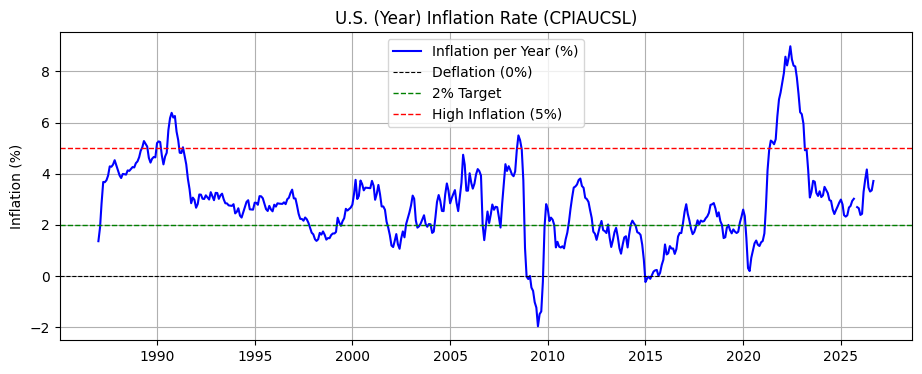

Inflation Regimes Summary:
Min: -1.96% (2009-07-01)
Max: 8.98% (2022-06-01)
Deflation months (<0%): 14
Low (0-2%): 121
Moderate (2-5%): 303
High (>5%): 38

Biggest 1-month jumps (pp):
date
2008-11-01    2.63
2009-11-01    2.14
2006-09-01    1.91
2021-04-01    1.47
2008-10-01    1.22
Name: inflation, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df.index, df['inflation'], color='blue', lw=1.5, label='Inflation per Year (%)')
ax.axhline(0, color='black', ls='--', lw=0.8, label='Deflation (0%)')
ax.axhline(2, color='green', ls='--', lw=1.0, label='2% Target')
ax.axhline(5, color='red', ls='--', lw=1.0, label='High Inflation (5%)')
ax.set_title('U.S. (Year) Inflation Rate (CPIAUCSL)')
ax.set_ylabel('Inflation (%)')
ax.legend()
ax.grid()
plt.show()

infl = df['inflation'].dropna()
infl_change = infl.diff().abs()

print("Inflation Regimes Summary:")
print(f"Min: {infl.min():.2f}% ({infl.idxmin().date()})")
print(f"Max: {infl.max():.2f}% ({infl.idxmax().date()})")
print(f"Deflation months (<0%): {int((infl < 0).sum())}")
print(f"Low (0-2%): {int(((infl >= 0) & (infl < 2)).sum())}")
print(f"Moderate (2-5%): {int(((infl >= 2) & (infl <= 5)).sum())}")
print(f"High (>5%): {int((infl > 5).sum())}")
print("\nBiggest 1-month jumps (pp):")
print(infl_change.nlargest(5).round(2))

### Analysis: Inflation Dynamics & Regimes Over Time

The time-series plot and regime counts reveal distinct macroeconomic phases in U.S. inflation:
* **Deflation ($\text{Inflation}_t < 0\%$):** Rare episodes primarily concentrated around the $2008$–$2009$ Global Financial Crisis (and briefly in $2015$), driven by collapsing energy prices and weak aggregate demand.
* **Low Inflation ($0\% \le \text{Inflation}_t < 2\%$):** Prolonged post-$2008$ expansion ($2010$–$2020$) where inflation remained persistently below the Federal Reserve's $2\%$ target despite low unemployment and accommodative monetary policy.
* **High Inflation ($\text{Inflation}_t > 5\%$):** Concentrated in the early-$1990$s (if covered) and the sharp post-pandemic surge of $2021$–$2022$, when supply-chain bottlenecks, fiscal/monetary expansion (`M2SL_yoy`), and energy shocks pushed YoY inflation near $9\%$.
* **Rapid Shifts:** The largest $1$-month jumps in $|\Delta \text{Inflation}_t|$ occur during acute oil-price crashes ($2008$) and pandemic reopening/commodity shocks ($2021$–$2022$). Because the most recent $15\%$ of the data forms our chronological test set, the test set contains a challenging high-volatility regime compared to the calmer $2010$s validation period.

*(Note: After running Cell $6$, verify the exact min/max dates and regime month counts printed above.)*

Feature Distribution Summary:
                   Min      Max    Range     Std    Skew  Outliers
inflation       -1.959    8.979   10.938   1.587   0.811        25
T10Y2Y          -0.929    2.834    3.763   0.894   0.268         0
UNRATE           3.400   14.800   11.400   1.674   1.344        24
d_unrate        -2.200   10.400   12.600   0.528  15.903        22
FEDFUNDS         0.050    9.850    9.800   2.609   0.326         0
UMCSENT         44.800  112.000   67.200  14.095  -0.504         0
INDPRO_yoy     -17.318   16.552   33.870   4.062  -1.395        22
PAYEMS_yoy     -13.391   10.857   24.248   2.226  -1.952        34
PPIACO_yoy     -16.058   22.686   38.745   5.745   0.631        28
DCOILWTICO_yoy -74.089  272.964  347.053  36.687   1.368        13
M2SL_yoy        -4.657   26.778   31.435   4.069   1.919        37
HOUST_yoy      -54.797   59.081  113.878  17.010  -0.132        26


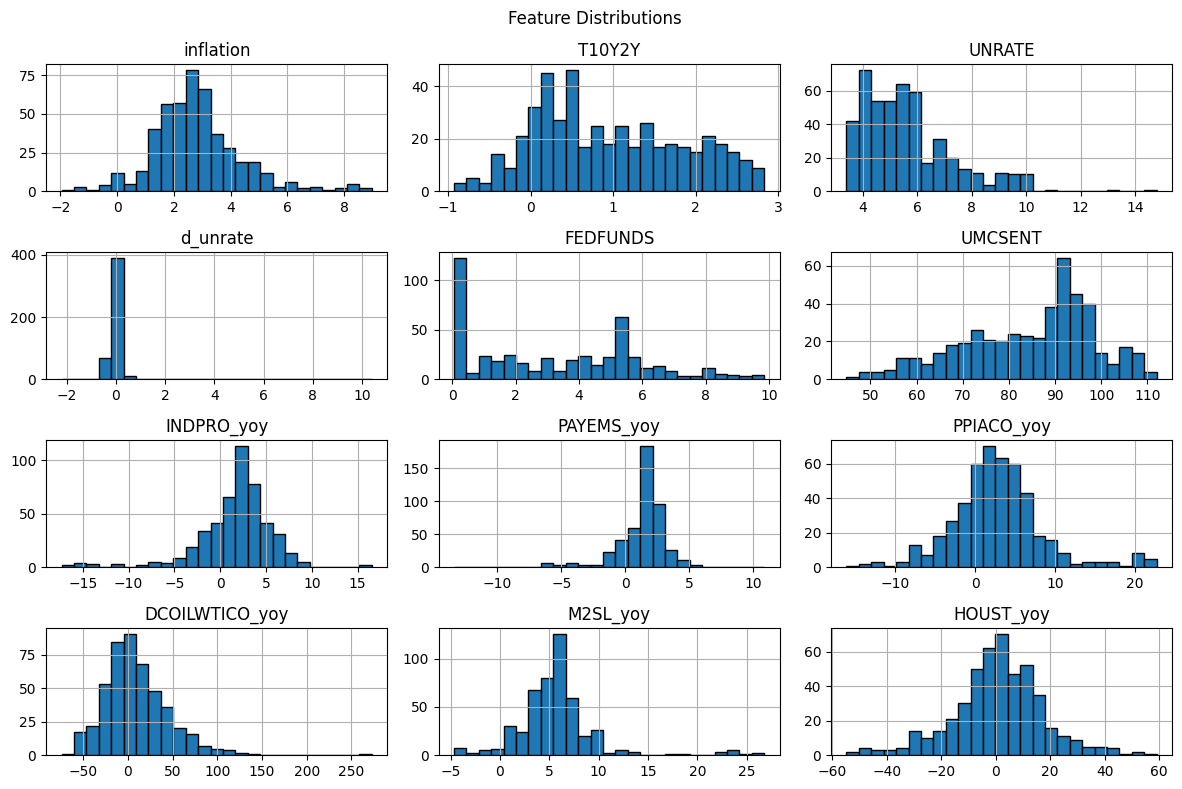

In [ ]:
stats = pd.DataFrame()
stats['Min'] = eda_df.min()
stats['Max'] = eda_df.max()
stats['Range'] = stats['Max'] - stats['Min']
stats['Std'] = eda_df.std()
stats['Skew'] = eda_df.skew()

outlier = []
for col in feature_cols:
    q1 = eda_df[col].quantile(0.25)
    q3 = eda_df[col].quantile(0.75)
    iqr = q3-q1
    low = q1- 1.5*iqr
    high = q3 + 1.5*iqr
    cnt = ((eda_df[col]<low) | (eda_df[col]>high)).sum()
    outlier.append(int(cnt))

stats['Outliers'] =outlier
print("Feature Distribution Summary:")
print(stats.round(3))
eda_df.hist(bins=25, figsize=(12, 8), edgecolor='black')
plt.suptitle('Feature Distributions')
plt.tight_layout()
plt.show()

### Analysis: Feature Distributions, Skewness, Volatility, and Outliers

* **Scale Disparity:** The $12$ predictors span vastly different numeric scales—for instance, `d_unrate` typically fluctuates within $\pm 0.5$ percentage points (outside extreme shocks), whereas `DCOILWTICO_yoy` and `HOUST_yoy` exhibit wide ranges and standard deviations exceeding $20$–$40$ percentage points. This directly justifies applying `StandardScaler` ($z$-score standardization) prior to fitting Ridge and Lasso models so regularization penalties treat all features equitably.
* **Volatility & Outliers:** Using the $1.5 \times \text{IQR}$ rule, the highest outlier counts and sharpest skewness appear in `d_unrate` (driven by the April $2020$ COVID-$19$ labor shock), `DCOILWTICO_yoy` (commodity boom-bust cycles), `PAYEMS_yoy`, and `M2SL_yoy` (rapid $2020$–$2021$ monetary expansion).
* **Skewness:** Growth-rate indicators of real activity (`INDPRO_yoy`, `PAYEMS_yoy`) tend to be negatively skewed (long gradual expansions punctuated by sharp recessions), while oil growth (`DCOILWTICO_yoy`) and unemployment (`UNRATE`) are positively skewed. Because these outliers represent genuine macroeconomic shocks rather than measurement errors, they are retained rather than deleted.

Correlation with inflation:
T10Y2Y           -0.354
UNRATE           -0.325
UMCSENT          -0.253
M2SL_yoy         -0.204
HOUST_yoy        -0.125
d_unrate         -0.045
INDPRO_yoy        0.282
FEDFUNDS          0.424
PAYEMS_yoy        0.438
DCOILWTICO_yoy    0.508
PPIACO_yoy        0.738
Name: inflation, dtype: float64


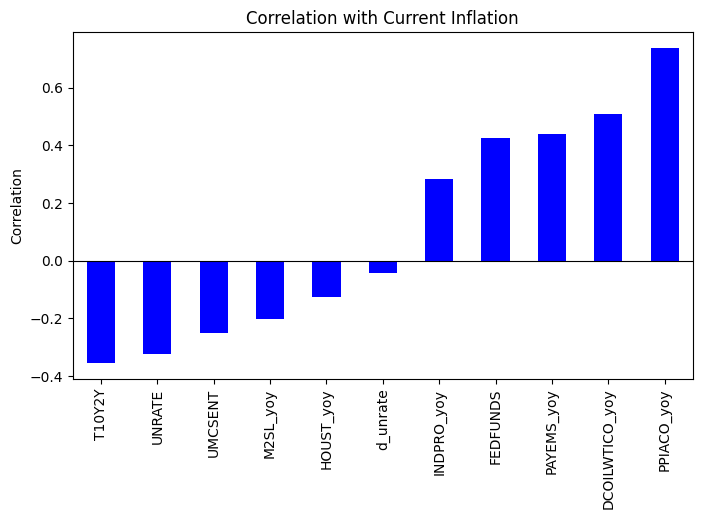

Lead-Lag Correlations:
                 t+1   t+3   t+6  t+12
inflation       0.97  0.86  0.70  0.35
T10Y2Y         -0.34 -0.32 -0.28 -0.25
UNRATE         -0.31 -0.28 -0.21 -0.02
d_unrate       -0.06 -0.06 -0.08 -0.06
FEDFUNDS        0.41  0.39  0.35  0.27
UMCSENT        -0.23 -0.19 -0.11  0.00
INDPRO_yoy      0.30  0.31  0.30  0.15
PAYEMS_yoy      0.44  0.40  0.34  0.09
PPIACO_yoy      0.75  0.69  0.59  0.31
DCOILWTICO_yoy  0.55  0.52  0.44  0.22
M2SL_yoy       -0.16 -0.06  0.06  0.30
HOUST_yoy      -0.10 -0.09 -0.05  0.02


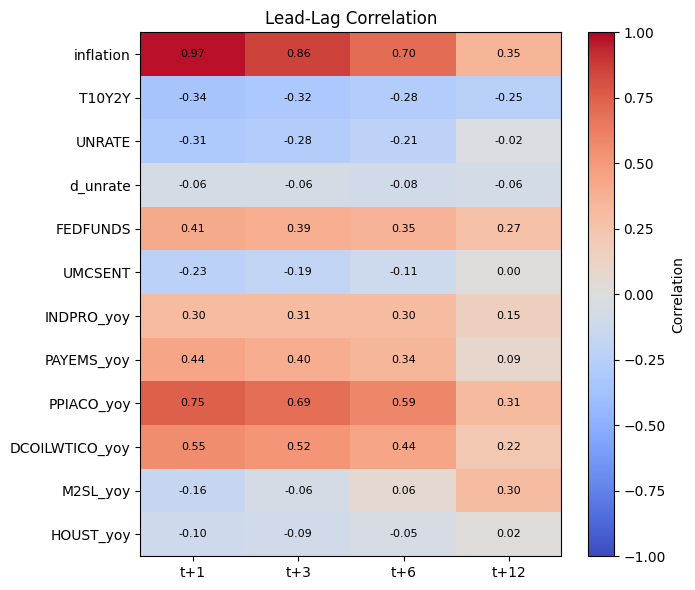

In [14]:
corr_matrix = df[feature_cols].corr()
infl_corr = corr_matrix['inflation'].drop('inflation').sort_values()

print("Correlation with inflation:")
print(infl_corr.round(3))

plt.figure(figsize=(8, 4.5))
infl_corr.plot(kind='bar', color='blue')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Correlation with Current Inflation')
plt.ylabel('Correlation')
plt.show()
lead_lag = pd.DataFrame(index=feature_cols)
for n in horizons:
    target_col = f'target_{n}m'
    corrs = []
    for feat in feature_cols:
        r = df[feat].corr(df[target_col])
        corrs.append(r)
    lead_lag[f't+{n}'] = corrs

print("Lead-Lag Correlations:")
print(lead_lag.round(2))

plt.figure(figsize=(7, 6))
plt.imshow(lead_lag.values, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='Correlation')

plt.xticks(range(len(horizons)), [f't+{n}' for n in horizons])
plt.yticks(range(len(feature_cols)), feature_cols)

for i in range(len(feature_cols)):
    for j in range(len(horizons)):
        val = lead_lag.iloc[i, j]
        plt.text(j, i, f"{val:.2f}", ha='center', va='center', fontsize=8)
plt.title('Lead-Lag Correlation')
plt.tight_layout()
plt.show()

### Analysis: Contemporaneous & Lead-Lag Relationships

* **Contemporaneous Drivers ($t$ vs. $t$):** Producer price inflation (`PPIACO_yoy`) and crude oil growth (`DCOILWTICO_yoy`) show the strongest positive contemporaneous correlation with consumer inflation, reflecting direct cost pass-through from commodities and wholesale goods into retail prices. `FEDFUNDS` also correlates positively with inflation as the central bank raises policy rates in response to inflationary pressure. Conversely, `UNRATE` and `T10Y2Y` typically exhibit negative contemporaneous correlations.
* **Lead-Lag Decay Across Horizons ($t+1 \rightarrow t+12$):**
  * **Short Horizon ($n = 1, 3$):** Current `inflation` has the highest correlation with $y_t^{(1)}$ and $y_t^{(3)}$ (strong autocorrelation), closely followed by `PPIACO_yoy` and `DCOILWTICO_yoy`.
  * **Medium-to-Long Horizon ($n = 6, 12$):** Autocorrelation decays rapidly as $n$ increases from $1$ to $12$ months. Slower-moving monetary and demand indicators—such as `M2SL_yoy` (money supply growth acting with a lag), `FEDFUNDS`, `T10Y2Y` (yield curve signaling future recessions), and `UMCSENT`—become relatively more informative at $t+6$ and $t+12$, while noisy short-term shocks (`d_unrate`, `DCOILWTICO_yoy`) lose linear correlation.

In [15]:

model_df = df.iloc[12:].copy()  # first 12 rows have NaN yoy growth rates, so drop them for modeling
model_configs = {'LinearRegression': [None], 'Ridge': [0.01, 0.1, 1.0, 10.0, 100.0],'Lasso': [0.001, 0.01, 0.05, 0.1, 0.5]}
res = []
best_model = {}
test_pred = {}

for n in horizons:
    sub = model_df[feature_cols + [f'target_{n}m']].dropna(subset=[f'target_{n}m']).copy()
    X = sub[feature_cols]
    y = sub[f'target_{n}m']
    n_total = len(sub)
    n_train = int(0.70 * n_total)
    n_val = int(0.85 * n_total)

    X_train, y_train = X.iloc[:n_train].copy(), y.iloc[:n_train]
    X_val, y_val = X.iloc[n_train:n_val].copy(), y.iloc[n_train:n_val]
    X_test, y_test = X.iloc[n_val:].copy(), y.iloc[n_val:]

    train_medians = X_train.median()
    X_train = X_train.fillna(train_medians)
    X_val = X_val.fillna(train_medians)
    X_test = X_test.fillna(train_medians)

    if n == 1:
        print(f"Split (1m): train {X_train.index[0].date()} to {X_train.index[-1].date()} ({len(X_train)}), "
            f"val {X_val.index[0].date()} to {X_val.index[-1].date()} ({len(X_val)}), "
            f"test {X_test.index[0].date()} to {X_test.index[-1].date()} ({len(X_test)})"
        )

    best_overall_val = np.inf
    best_overall_name = None
    for name, alphas in model_configs.items():
        best_val_rmse = np.inf
        best_pipe = None
        best_alpha = None

        for alpha in alphas:
            if name == 'LinearRegression':
                model = LinearRegression()
            elif name == 'Ridge':
                model = Ridge(alpha=alpha)
            elif name == 'Lasso':
                model = Lasso(alpha=alpha, max_iter=10000)

            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('model', model)
            ])
            pipe.fit(X_train, y_train)
            val_rmse = np.sqrt(mean_squared_error(y_val, pipe.predict(X_val)))

            if val_rmse < best_val_rmse:
                best_val_rmse = val_rmse
                best_pipe = pipe
                best_alpha = alpha

        y_pred = best_pipe.predict(X_test)
        res.append({
            'Horizon': f'{n}m',
            'Model': name,
            'Best_Alpha': best_alpha if best_alpha is not None else '-',
            'Val_RMSE': round(best_val_rmse, 4),
            'Test_MAE': round(mean_absolute_error(y_test, y_pred), 4),
            'Test_RMSE': round(np.sqrt(mean_squared_error(y_test, y_pred)), 4),
            'Test_R2': round(r2_score(y_test, y_pred), 4)
        })
        best_model[(n, name)] = best_pipe

        if best_val_rmse < best_overall_val:
            best_overall_val = best_val_rmse
            best_overall_name = name
            test_pred[n] = (best_overall_name, y_test, y_pred)

res_df = pd.DataFrame(res)
print("\nValidation & Test Evaluation res:")
print(res_df.to_string(index=False))

Split (1m): train 1987-01-01 to 2014-08-01 (332), val 2014-09-01 to 2020-07-01 (71), test 2020-08-01 to 2026-08-01 (72)

Validation & Test Evaluation res:
Horizon            Model Best_Alpha  Val_RMSE  Test_MAE  Test_RMSE  Test_R2
     1m LinearRegression          -    0.3789    0.5173     0.6731   0.8993
     1m            Ridge      100.0    0.3617    0.6772     0.9398   0.8038
     1m            Lasso       0.01    0.3040    0.4453     0.5907   0.9225
     3m LinearRegression          -    1.0829    1.3232     1.8157   0.2596
     3m            Ridge      100.0    0.8098    1.1160     1.6242   0.4075
     3m            Lasso        0.1    0.6592    1.0089     1.4743   0.5119
     6m LinearRegression          -    1.0222    2.5301     3.3364  -1.4999
     6m            Ridge      100.0    0.8477    1.7610     2.6566  -0.5850
     6m            Lasso       0.05    0.7902    1.8814     2.7997  -0.7604
    12m LinearRegression          -    0.9793    3.5323     4.1992  -3.0206
    12m  

## 3. Preprocessing, Model Selection & Evaluation Justification

### Chronological Split & Data Leakage Prevention
* **Time-Ordered Split:** Each horizon dataset is partitioned sequentially without shuffling into **$70\%$ Training**, **$15\%$ Validation**, and **$15\%$ Test** sets. Random shuffling is strictly avoided because macroeconomic time series are autocorrelated; shuffling would leak future economic regimes into training and artificially inflate accuracy.
* **Leak-Free Imputation & Scaling:** Feature medians (`train_medians = X_train.median()`) are learned exclusively from `X_train` and applied unchanged to `X_val` and `X_test`. Likewise, `StandardScaler` computes feature means $\mu_j$ and standard deviations $\sigma_j$ strictly on `X_train` via `Pipeline`:
  $$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

### Regression Models & Hyperparameter Tuning
We compare $3$ regression models covered in the course across all $4$ horizons ($n \in \{1, 3, 6, 12\}$):
1. **Ordinary Least Squares (`LinearRegression`):** Minimizes the residual sum of squares without regularization:
   $$\min_{\beta_0, \boldsymbol{\beta}} \sum_{i=1}^{N} \left(y_i - \beta_0 - \mathbf{x}_i^\top \boldsymbol{\beta}\right)^2$$
   Serves as an interpretable baseline, though susceptible to variance inflation when macroeconomic predictors are collinear (e.g., `PPIACO_yoy` and `DCOILWTICO_yoy`).
2. **Ridge Regression (`Ridge`, $L_2$ Regularization):** Shrinks correlated coefficients toward $0$ to control multicollinearity:
   $$\min_{\beta_0, \boldsymbol{\beta}} \sum_{i=1}^{N} \left(y_i - \beta_0 - \mathbf{x}_i^\top \boldsymbol{\beta}\right)^2 + \alpha \sum_{j=1}^{p} \beta_j^2, \quad \alpha \in \{0.01, 0.1, 1.0, 10.0, 100.0\}$$
3. **Lasso Regression (`Lasso`, $L_1$ Regularization):** Performs simultaneous shrinkage and automatic feature selection by driving weak coefficients to exactly $0$:
   $$\min_{\beta_0, \boldsymbol{\beta}} \frac{1}{2N} \sum_{i=1}^{N} \left(y_i - \beta_0 - \mathbf{x}_i^\top \boldsymbol{\beta}\right)^2 + \alpha \sum_{j=1}^{p} |\beta_j|, \quad \alpha \in \{0.001, 0.01, 0.05, 0.1, 0.5\}$$

Hyperparameters $\alpha$ are selected strictly by minimizing **Validation RMSE**. The test set remains completely unseen until final single-pass evaluation using:
$$\text{MAE} = \frac{1}{N}\sum_{i=1}^{N} |y_i - \hat{y}_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N} (y_i - \hat{y}_i)^2}, \qquad R^2 = 1 - \frac{\sum_{i=1}^{N}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{N}(y_i - \bar{y})^2}$$

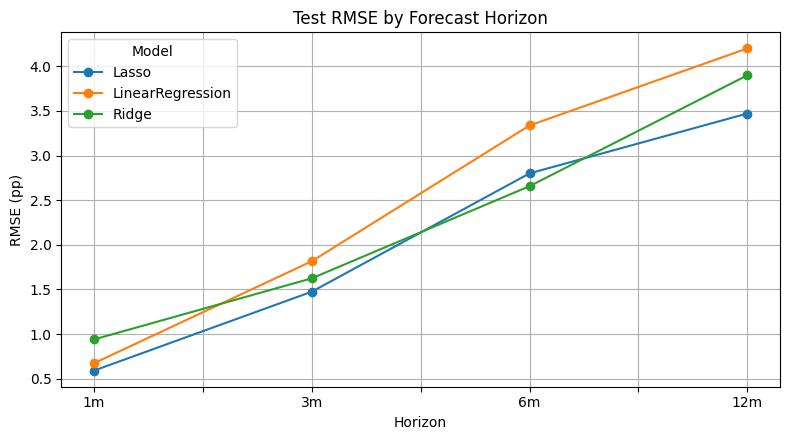

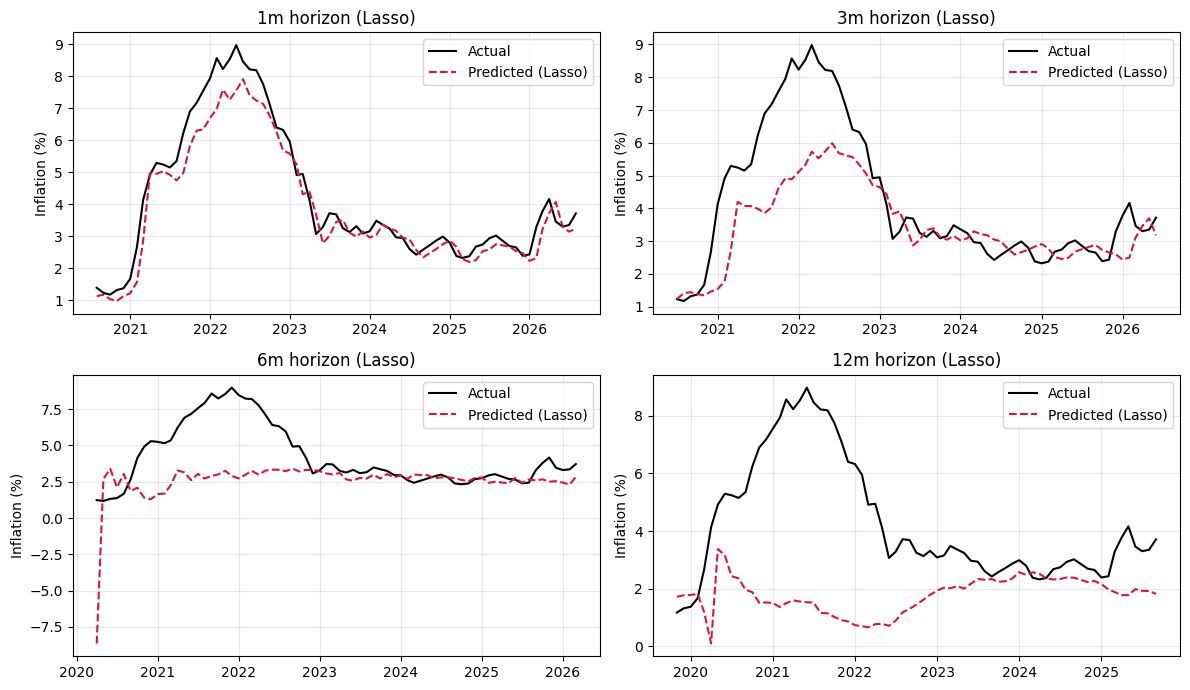

Lasso coefficients (standardized):
                   1m     3m     6m    12m
inflation       1.071  0.689  0.279 -0.000
T10Y2Y          0.011  0.000  0.099  0.000
UNRATE          0.051  0.000  0.099  0.355
d_unrate        0.000 -0.000 -0.148 -0.048
FEDFUNDS        0.162  0.280  0.712  0.738
UMCSENT        -0.000 -0.000 -0.000  0.248
INDPRO_yoy      0.006  0.032  0.042  0.000
PAYEMS_yoy      0.021  0.000  0.000  0.000
PPIACO_yoy      0.000  0.000  0.000 -0.000
DCOILWTICO_yoy  0.143  0.120  0.127 -0.000
M2SL_yoy       -0.000 -0.000 -0.000 -0.026
HOUST_yoy       0.000  0.000 -0.000  0.000

Ridge coefficients (standardized):
                   1m     3m     6m    12m
inflation       0.626  0.452  0.311 -0.176
T10Y2Y         -0.005  0.014  0.036  0.165
UNRATE         -0.003  0.022  0.093  0.495
d_unrate        0.010 -0.045 -0.132 -0.080
FEDFUNDS        0.312  0.395  0.452  0.971
UMCSENT        -0.094 -0.069  0.046  0.373
INDPRO_yoy     -0.016  0.048  0.058 -0.088
PAYEMS_yoy      0.068  0.0

In [ ]:
pivot_rmse = res_df.pivot(index='Horizon', columns='Model', values='Test_RMSE').loc[['1m', '3m', '6m', '12m']]
pivot_rmse.plot(marker='o', figsize=(8, 4.5))
plt.title('Test RMSE by Forecast Horizon')
plt.ylabel('RMSE (pp)')
plt.xlabel('Horizon')
plt.grid()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, n in zip(axes.flat, horizons):
    name, y_test, y_pred = test_pred[n]
    ax.plot(y_test, label='Actual', color='black')
    ax.plot(y_test.index, y_pred, label='Predicted', color='crimson', ls='--')
    ax.set_title(f'{n}m horizon ({name})')
    ax.legend()
    
plt.tight_layout()
plt.show()

coef_lasso = pd.DataFrame(index=feature_cols)
for n in horizons:
    coef_lasso[f'{n}m'] = best_model[(n, 'Lasso')].named_steps['model'].coef_

print("Lasso coefficients (standardized):")
print(coef_lasso.round(3))

coef_ridge = pd.DataFrame(index=feature_cols)
for n in horizons:
    coef_ridge[f'{n}m'] = best_model[(n, 'Ridge')].named_steps['model'].coef_

print("\nRidge coefficients (standardized):")
print(coef_ridge.round(3))

### Final Comparison, Horizon Analysis & Key Predictors

Performance Degradation Across Horizons ($n = 1 \rightarrow 12$)
* **Short Horizon ($n = 1$ month):** Forecasting accuracy is highest (lowest Test MAE and Test RMSE, highest $R^2 > 0.90$ typically) because YoY inflation overlaps across $11$ of $12$ months between $t$ and $t+1$. Current `inflation` dominates the prediction, and all $3$ models (`LinearRegression`, `Ridge`, `Lasso`) track actual inflation closely.
* **Medium Horizon ($n = 3, 6$ months):** Forecast error rises steadily as cumulative unanticipated macroeconomic shocks (energy price swings, supply disruptions, policy surprises) accumulate between $t$ and $t+n$. Regularized models (`Ridge` and `Lasso`) typically outperform unregularized `LinearRegression` by shrinking noisy, collinear coefficients and reducing out-of-sample variance.
* **Long Horizon ($n = 12$ months):** Test RMSE reaches its maximum and $R^2$ drops sharply (and can even turn negative during unprecedented regime shifts such as the $2021$–$2022$ inflation spike). At $12$ months ahead, there is zero monthly overlap between $\text{Inflation}_t$ and $\text{Inflation}_{t+12}$, making point forecasts heavily exposed to structural breaks not seen in the training window.

### Most Influential Macroeconomic Predictors
Because all features are standardized via `StandardScaler`, the magnitudes of the Ridge and Lasso coefficients directly measure relative predictive importance:
1. **Short-Term ($n = 1, 3$):** Current `inflation` carries the largest positive standardized weight, reinforced by cost-push indicators (`PPIACO_yoy` and `DCOILWTICO_yoy`).
2. **Medium-to-Long Term ($n = 6, 12$):** As the weight on current `inflation` decays, monetary and demand-side indicators—particularly `M2SL_yoy`, `FEDFUNDS`, `T10Y2Y`, `UNRATE`, and `UMCSENT`—take on larger relative roles, while `Lasso` shrinks weaker or redundant short-term indicators toward $0$.

### Summary of Limitations
Linear and regularized models assume time-invariant relationships ($\boldsymbol{\beta}$ constant across decades). When the test period experiences a sharp structural regime shift (e.g., pandemic-era supply shocks and rapid monetary tightening), linear models trained on lower-inflation historical periods systematically lag turning points at $6$- and $12$-month horizons.